# Can Weather Predict Air Pollution in Berlin? A Bayesian Regression Analysis of Temperature, Wind Speed, and Nitrogen Dioxide Concentrations
**to what extent can daily weather conditions predict NO₂ concentrations in Berlin, and does adding model complexity improve predictions on unseen days?**

The code is based on the pre class work notebooks from:
- CS146 Session 7 (linear regression, prior/posterior checks)
- CS146 Session 8,(thinking about outliers and robust regression)
- CS146 Session 9, (polynomial regression)
- CS146 Session 10, (underfitting, overfitting, and model comparison)


## Introduction

I use daily NO₂ measurements from one Berlin traffic-monitoring station and daily weather data for 2025.  
The models are predictive, not causal: a regression coefficient describes an association in this data set, not proof that changing temperature or wind would directly cause NO₂ to change.

In [1]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import arviz as az

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

#to make it more reproducible
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

#for the 89% credible intervals
az.rcParams["stats.ci_prob"] = 0.89

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


## DATA COLLECTION

## Data Sources

**Air pollution:** Berliner Luftgütemessnetz, Station 221 Karl-Marx-Straße.  
The file contains daily values for PM10, PM2.5, NO₂, NO, and NOx. I only use NO₂ as the response variable.

**Weather:** Open-Meteo Historical Weather API.  
I use daily mean temperature at 2 m, precipitation sum, and maximum wind speed at 10 m.

The two sources are merged by date. The weather data are reanalysis estimates on a spatial grid, not measurements from an instrument attached to the pollution station.

In [2]:
#importing data from weather
#first 3 rows is metadata
weather = pd.read_csv("berlin_weather_2025.csv", skiprows=3)

print(weather.head())

         time  temperature_2m_mean (°C)  precipitation_sum (mm)  \
0  2025-01-01                       4.5                     0.0   
1  2025-01-02                       4.4                     4.0   
2  2025-01-03                       1.0                     4.6   
3  2025-01-04                      -0.9                     0.0   
4  2025-01-05                      -1.0                     8.8   

   wind_speed_10m_max (km/h)  
0                       25.9  
1                       26.1  
2                       29.4  
3                       19.5  
4                       18.2  


In [3]:
weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean (°C)": "temp_mean",
    "precipitation_sum (mm)": "precip",
    "wind_speed_10m_max (km/h)": "wind_max"
})

weather["date"] = pd.to_datetime(weather["date"])
print(weather.head())

        date  temp_mean  precip  wind_max
0 2025-01-01        4.5     0.0      25.9
1 2025-01-02        4.4     4.0      26.1
2 2025-01-03        1.0     4.6      29.4
3 2025-01-04       -0.9     0.0      19.5
4 2025-01-05       -1.0     8.8      18.2


In [4]:
#now loading the pollution data csv
#semicolon-separated, with 5 metadata/header rows above the daily data
#also my bad because the filename says 2026, but the observations inside that I selected to download are for 2025.
pollution = pd.read_csv(
    "NO2_pollution_2026.csv",
    sep=";",
    skiprows=5,
    header=None,
    names=["date", "pm10", "pm25", "no2", "no", "nox"]
)

pollution["date"] = pd.to_datetime(pollution["date"], format="%d.%m.%Y")
print(pollution.head())

        date  pm10  pm25  no2  no  nox
0 2025-01-01  27.0  20.0   10   6   19
1 2025-01-02  11.0   7.0   19   9   32
2 2025-01-03   7.0   6.0   15   7   25
3 2025-01-04  13.0  11.0   21  10   36
4 2025-01-05  19.0  16.0   20   5   27


In [5]:
#merge both files data by date
df = pd.merge(pollution, weather, on="date", how="inner")

# to keep only variables that are relevant to this analysis to clean the data
data = df[["date", "no2", "temp_mean", "precip", "wind_max"]].copy()

print("Rows:", len(data))
print("\nMissing values:")
print(data.isna().sum())
print("\nSummary statistics:")

Rows: 365

Missing values:
date         0
no2          0
temp_mean    0
precip       0
wind_max     0
dtype: int64

Summary statistics:


Explanatory Data Analysis

In [6]:
display(data.describe())

,date,no2,temp_mean,precip,wind_max
count,365,365.000000,365.000000,365.000000,365.000000
mean,2025-07-02 00:00:00,22.336986,10.800548,1.633973,15.336438
min,2025-01-01 00:00:00,8.000000,-7.500000,0.000000,5.100000
25%,2025-04-02 00:00:00,15.000000,4.900000,0.000000,11.600000
50%,2025-07-02 00:00:00,21.000000,11.000000,0.100000,14.800000
75%,2025-10-01 00:00:00,27.000000,17.300000,1.500000,18.500000
max,2025-12-31 00:00:00,67.000000,29.600000,41.400000,32.700000
std,NaN,9.826454,7.475789,3.630790,5.094073


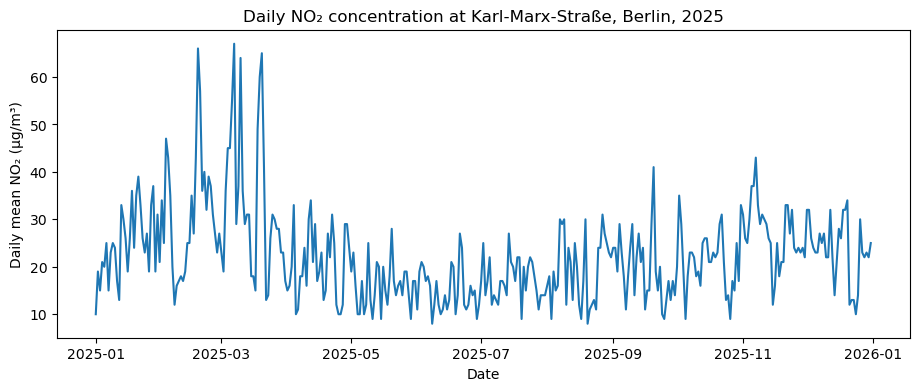

In [7]:
# Daily NO2 through the year
plt.figure(figsize=(11, 4))
plt.plot(data["date"], data["no2"])
plt.xlabel("Date")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Daily NO₂ concentration at Karl-Marx-Straße, Berlin, 2025")
plt.show()

## MODELING

Temperature vs NO2

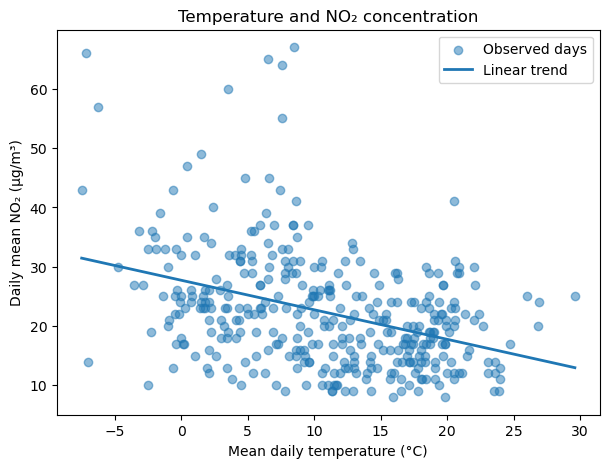

In [17]:
# relationship between temperature and NO2
plt.figure(figsize=(7, 5))

plt.scatter(
    data["temp_mean"],
    data["no2"],
    alpha=0.5,
    label="Observed days"
)

# added a simple linear trend line for visualization only
slope, intercept = np.polyfit(
    data["temp_mean"],
    data["no2"],
    1
)

x_line = np.linspace(
    data["temp_mean"].min(),
    data["temp_mean"].max(),
    100
)

y_line = intercept + slope * x_line

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear trend"
)

plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Temperature and NO₂ concentration")
plt.legend()

plt.show()

Wind vs NO2

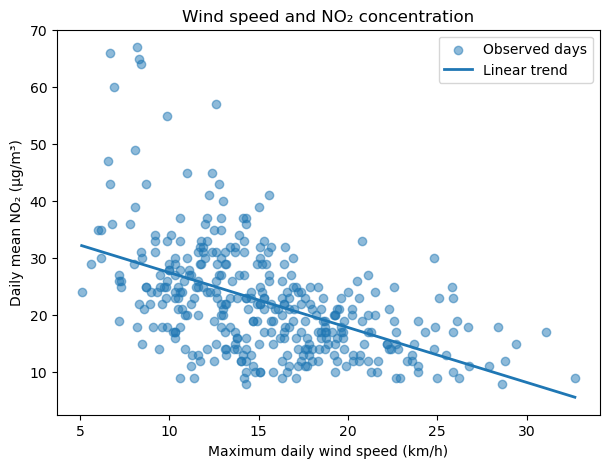

In [18]:
plt.figure(figsize=(7, 5))

plt.scatter(
    data["wind_max"],
    data["no2"],
    alpha=0.5,
    label="Observed days"
)

# added a simple linear trend for visualization
slope, intercept = np.polyfit(
    data["wind_max"],
    data["no2"],
    1
)

x_line = np.linspace(
    data["wind_max"].min(),
    data["wind_max"].max(),
    100
)

y_line = intercept + slope * x_line

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear trend"
)

plt.xlabel("Maximum daily wind speed (km/h)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Wind speed and NO₂ concentration")
plt.legend()

plt.show()

Precipitation vs NO2

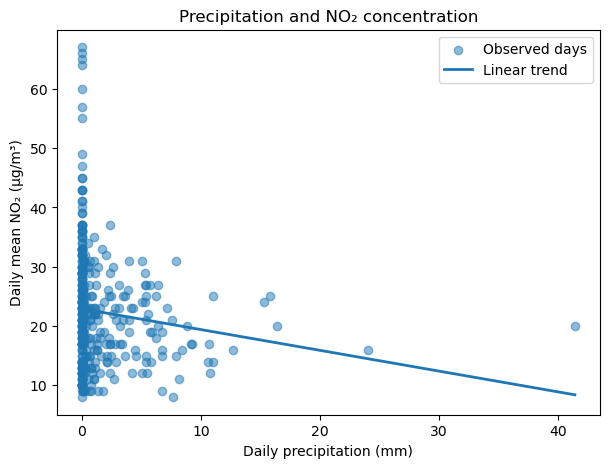

In [19]:
plt.figure(figsize=(7, 5))

plt.scatter(
    data["precip"],
    data["no2"],
    alpha=0.5,
    label="Observed days"
)

slope, intercept = np.polyfit(
    data["precip"],
    data["no2"],
    1
)

x_line = np.linspace(
    data["precip"].min(),
    data["precip"].max(),
    100
)

y_line = intercept + slope * x_line

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear trend"
)

plt.xlabel("Daily precipitation (mm)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Precipitation and NO₂ concentration")
plt.legend()

plt.show()

In [20]:
# Simple correlations are descriptive only; they are not causal effects.
corr = data[["no2", "temp_mean", "precip", "wind_max"]].corr()
display(corr.round(3))

# Monthly means help show the seasonal structure
monthly = data.groupby(data["date"].dt.month).agg(
    mean_no2=("no2", "mean"),
    mean_temp=("temp_mean", "mean"),
    mean_wind=("wind_max", "mean")
)
display(monthly.round(2))

# Inspect the largest NO2 values instead of deleting them automatically
display(data.nlargest(10, "no2"))

,no2,temp_mean,precip,wind_max
no2,1.000,-0.379,-0.129,-0.499
temp_mean,-0.379,1.000,0.122,0.138
precip,-0.129,0.122,1.000,0.249
wind_max,-0.499,0.138,0.249,1.000


,mean_no2,mean_temp,mean_wind
date,,,
1,24.65,2.39,18.12
2,31.18,0.70,12.34
3,33.74,6.33,12.22
4,20.43,12.22,14.30
5,15.94,14.05,17.13
6,14.90,19.90,19.40
7,17.16,19.66,15.38
8,19.23,19.02,13.46
9,19.50,15.82,15.45


,date,no2,temp_mean,precip,wind_max
65,2025-03-07,67,8.5,0.0,8.2
48,2025-02-18,66,-7.2,0.0,6.7
78,2025-03-20,65,6.5,0.0,8.3
68,2025-03-10,64,7.6,0.0,8.4
77,2025-03-19,60,3.5,0.0,6.9
49,2025-02-19,57,-6.3,0.0,12.6
64,2025-03-06,55,7.6,0.0,9.9
76,2025-03-18,49,1.5,0.0,8.1
33,2025-02-03,47,0.4,0.0,6.6
62,2025-03-04,45,4.8,0.0,11.0


## Exploratory Data Analysis interpretation

Based on the plots I can see that temperature and wind both have negative simple associations with NO₂. Wind has the stronger correlation, while precipitation is much weaker. I also see several unusually high NO₂ days in late winter and early spring.

This motivate me to create the following models:
1. a simple temperature-only baseline
2. a multiple regression adding wind, because wind is physically connected to pollutant dispersion and has a clear empirical association in the data
3. a quadratic temperature model with wind (temperature + temperature² + wind), to test whether extra nonlinear complexity improves prediction

I will not add precipitation to the main models just because it is available. Its simple association is weak, and adding predictors without a clear reason can make interpretation harder.


## Train-Test Split and Standardization
### Random 80/20 test split

In [21]:
train, test = train_test_split(
    data,
    test_size=0.20,
    random_state=RANDOM_SEED
)

train = train.copy()
test = test.copy()

print("Training observations:", len(train))
print("Test observations:", len(test))


Training observations: 292
Test observations: 73


I will compute predictor means and standar deviations only from the training data (so information from the test set leaking into model fitting)

In [22]:
scaling = {}

for col in ["temp_mean", "wind_max", "precip"]:
    mean = train[col].mean()
    sd = train[col].std()
    scaling[col] = (mean, sd)

    train[col + "_std"] = (train[col] - mean) / sd
    test[col + "_std"] = (test[col] - mean) / sd

# Polynomial term for Model 3
train["temp_std2"] = train["temp_mean_std"] ** 2
test["temp_std2"] = test["temp_mean_std"] ** 2

display(pd.DataFrame(
    scaling,
    index=["training mean", "training sd"]
).T)

,training mean,training sd
temp_mean,11.245890,7.472365
wind_max,15.590411,5.097871
precip,1.513014,3.451117


In [36]:
# Save training-set means and standard deviations
temp_mean_train = train["temp_mean"].mean()
temp_sd_train = train["temp_mean"].std()

wind_mean_train = train["wind_max"].mean()
wind_sd_train = train["wind_max"].std()

# Make copies so we can safely add columns
train = train.copy()
test = test.copy()

# Standardize using TRAINING data only
train["temp_std"] = (
    train["temp_mean"] - temp_mean_train
) / temp_sd_train

train["wind_std"] = (
    train["wind_max"] - wind_mean_train
) / wind_sd_train

# Use the SAME training-set scaling for test data
test["temp_std"] = (
    test["temp_mean"] - temp_mean_train
) / temp_sd_train

test["wind_std"] = (
    test["wind_max"] - wind_mean_train
) / wind_sd_train

## Bayesian Regression Models
All three models use a Normal likelihood for daily NO₂. The predictors are standardized, so a slope is the expected difference in NO₂ associated with a one-standard-deviation increase in that predictor, holding the other predictors fixed.

And I am using the same priors in all models:
$$
a \sim \text{Normal}(25, 15)
$$

for the intercept,

$$
b \sim \text{Normal}(0, 5)
$$

for each regression coefficient, and

$$
\sigma \sim \text{Uniform}(0, 30)
$$

The slope prior is symmetric because I do not want to force the weather association to be positive or negative. 


## Model 1: Temperature Only
$$
NO_{2,i} \sim \text{Normal}(\mu_i, \sigma)
$$

$$
\mu_i = \alpha + \beta_T T_i
$$
where $T_i$ is standardized temperature.

In [29]:
with pm.Model() as model_1:
    # Priors
    a = pm.Normal("a", mu=25, sigma=15)
    b_temp = pm.Normal("b_temp", mu=0, sigma=5)
    sigma = pm.Uniform("sigma", lower=0, upper=30)

    # Training predictor
    x_temp = pm.Data("x_temp", train["temp_mean_std"].values)

    # Linear regression mean
    mu = pm.Deterministic("mu", a + b_temp * x_temp)

    # Likelihood
    pm.Normal(
        "likelihood",
        mu=mu,
        sigma=sigma,
        observed=train["no2"].values
    )

    # Prior-predictive and posterior samples
    prior_1 = pm.sample_prior_predictive(
        samples=500,
        random_seed=RANDOM_SEED
    )

    idata_1 = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=RANDOM_SEED
    )
    

Sampling: [a, b_temp, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [a, b_temp, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 694 seconds.


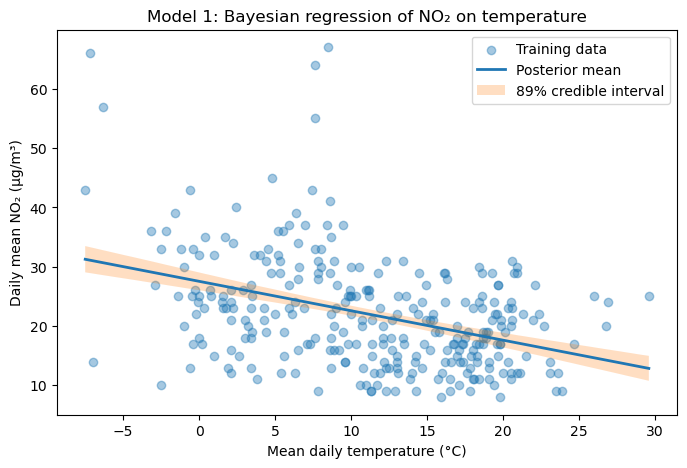

In [31]:

# to visualize the posterior regression relationship for Model 1

temp_mean_train = train["temp_mean"].mean()
temp_sd_train = train["temp_mean"].std()

temp_grid_original = np.linspace(
    train["temp_mean"].min(),
    train["temp_mean"].max(),
    100
)

temp_grid_std = (
    temp_grid_original - temp_mean_train
) / temp_sd_train

a_samples = idata_1.posterior["a"].values.flatten()
b_samples = idata_1.posterior["b_temp"].values.flatten()

mu_samples = (
    a_samples[:, None]
    + b_samples[:, None] * temp_grid_std[None, :]
)

mu_mean = mu_samples.mean(axis=0)
mu_lower = np.quantile(mu_samples, 0.055, axis=0)
mu_upper = np.quantile(mu_samples, 0.945, axis=0)

plt.figure(figsize=(8, 5))

plt.scatter(
    train["temp_mean"],
    train["no2"],
    alpha=0.4,
    label="Training data"
)

plt.plot(
    temp_grid_original,
    mu_mean,
    linewidth=2,
    label="Posterior mean"
)

plt.fill_between(
    temp_grid_original,
    mu_lower,
    mu_upper,
    alpha=0.25,
    label="89% credible interval"
)

plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Model 1: Bayesian regression of NO₂ on temperature")

plt.legend()
plt.show()

## Model 2: temperature and Wind

$$
NO_{2,i} \sim \text{Normal}(\mu_i, \sigma)
$$

$$
\mu_i = \alpha + \beta_T T_i + \beta_W W_i
$$

In [ ]:
with pm.Model() as model_2:

    # Priors
    a = pm.Normal(
        "a",
        mu=25,
        sigma=15
    )

    b_temp = pm.Normal(
        "b_temp",
        mu=0,
        sigma=5
    )

    b_wind = pm.Normal(
        "b_wind",
        mu=0,
        sigma=5
    )

    sigma = pm.Uniform(
        "sigma",
        lower=0,
        upper=30
    )

    # Expected NO2
    mu = (
        a
        + b_temp * train["temp_std"].values
        + b_wind * train["wind_std"].values
    )

    # Likelihood
    pm.Normal(
        "likelihood",
        mu=mu,
        sigma=sigma,
        observed=train["no2"].values
    )

    # Prior predictive samples
    prior_2 = pm.sample_prior_predictive(
        samples=500,
        random_seed=RANDOM_SEED
    )

    # Posterior sampling
    idata_2 = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
        return_inferencedata=True
    )


Sampling: [a, b_temp, b_wind, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [a, b_temp, b_wind, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [ ]:
#run form here
# Posterior samples from Model 2
a_samples = idata_2.posterior["a"].values.flatten()
b_temp_samples = idata_2.posterior["b_temp"].values.flatten()

# Wind is held at its mean, so standardized wind = 0
mu_samples = (
    a_samples[:, None]
    + b_temp_samples[:, None] * temp_grid_std[None, :]
)

mu_mean = mu_samples.mean(axis=0)

mu_lower = np.quantile(mu_samples, 0.055, axis=0)
mu_upper = np.quantile(mu_samples, 0.945, axis=0)

plt.figure(figsize=(8, 5))

plt.scatter(
    train["temp_mean"],
    train["no2"],
    alpha=0.35
)

plt.plot(
    temp_grid_original,
    mu_mean,
    linewidth=2,
    label="Posterior mean"
)

plt.fill_between(
    temp_grid_original,
    mu_lower,
    mu_upper,
    alpha=0.25,
    label="89% credible interval"
)

plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title(
    "Model 2: Temperature effect with wind held at its mean"
)

plt.legend()
plt.show()

## Model 3: Quadratic temperature and wind

$$
NO_{2,i} \sim \text{Normal}(\mu_i, \sigma)
$$

$$
\mu_i = \alpha + \beta_T T_i + \beta_{T^2} T_i^2 + \beta_W W_i
$$

This is still a linear regression model because it is linear in the coefficients, even though the fitted relationship can curve as a function of temperature. (like the polynomial-regression approach from Session 9)

In [ ]:
with pm.Model() as model_3:
    a = pm.Normal("a", mu=25, sigma=15)
    b_temp = pm.Normal("b_temp", mu=0, sigma=5)
    b_temp2 = pm.Normal("b_temp2", mu=0, sigma=5)
    b_wind = pm.Normal("b_wind", mu=0, sigma=5)
    sigma = pm.Uniform("sigma", lower=0, upper=30)

    x_temp = pm.Data("x_temp", train["temp_mean_std"].values)
    x_temp2 = pm.Data("x_temp2", train["temp_std2"].values)
    x_wind = pm.Data("x_wind", train["wind_max_std"].values)

    mu = pm.Deterministic(
        "mu",
        a
        + b_temp * x_temp
        + b_temp2 * x_temp2
        + b_wind * x_wind
    )

    pm.Normal(
        "likelihood",
        mu=mu,
        sigma=sigma,
        observed=train["no2"].values
    )

    prior_3 = pm.sample_prior_predictive(
        samples=500,
        random_seed=RANDOM_SEED
    )

    idata_3 = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=RANDOM_SEED
    )

Sampling: [a, b_temp, b_temp2, b_wind, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a, b_temp, b_temp2, b_wind, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

ValueError: Not enough samples to build a trace.

In [ ]:
a_samples = idata_3.posterior["a"].values.flatten()
b_temp_samples = idata_3.posterior["b_temp"].values.flatten()
b_temp2_samples = idata_3.posterior["b_temp2"].values.flatten()

mu_samples = (
    a_samples[:, None]
    + b_temp_samples[:, None] * temp_grid_std[None, :]
    + b_temp2_samples[:, None] * temp_grid_std[None, :]**2
)

mu_mean = mu_samples.mean(axis=0)

mu_lower = np.quantile(mu_samples, 0.055, axis=0)
mu_upper = np.quantile(mu_samples, 0.945, axis=0)

plt.figure(figsize=(8, 5))

plt.scatter(
    train["temp_mean"],
    train["no2"],
    alpha=0.35
)

plt.plot(
    temp_grid_original,
    mu_mean,
    linewidth=2,
    label="Posterior mean"
)

plt.fill_between(
    temp_grid_original,
    mu_lower,
    mu_upper,
    alpha=0.25,
    label="89% credible interval"
)

plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title(
    "Model 3: Quadratic temperature relationship\n"
    "with wind held at its mean"
)

plt.legend()
plt.show()

## Prior, Posterior, and Posterior-Predictive Checks

In class it told us to check what the model can generate before seeing the data. I compare the Model 2 prior-predictive distribution with the observed training data. I expect the prior prediction to be much broader than the data, but it should still put substantial probability on NO₂ values in the observed range.

In [ ]:
# Prior-predictive check for Model 2
prior_y = prior_2.prior_predictive["likelihood"].values.ravel()

plt.figure(figsize=(7, 4))
plt.hist(
    prior_y,
    bins=60,
    density=True,
    alpha=0.45,
    label="Prior predictive"
)
plt.hist(
    train["no2"],
    bins=25,
    density=True,
    alpha=0.60,
    label="Observed training data"
)
plt.xlabel("Daily mean NO₂ (µg/m³)")
plt.ylabel("Density")
plt.title("Prior-predictive check for Model 2")
plt.legend()
plt.show()

print("Prior predictive 5th and 95th percentiles:",
      np.quantile(prior_y, [0.05, 0.95]))

Because the likelihood is Normal, the prior predictive distribution can include some negative NO₂ values, which are not physically possible. This can be a limitation of the Gaussian approximation not neccesarily evidence that negative concentrations are expected. The prior remains intentionally broad and does not force the posterior toward a particular weather effect.

In [ ]:
#creating a helper function for sampler diagnostics
def sampler_diagnostics(idata, var_names):
    summary = az.summary(idata, var_names=var_names, round_to=2)
    divergences = int(idata.sample_stats["diverging"].sum().values)

    display(summary)
    print("Divergences:", divergences)

    az.plot_rank(idata, var_names=var_names)
    plt.show()

    return summary

In [ ]:
print("Model 1 diagnostics")
summary_1 = sampler_diagnostics(
    idata_1,
    ["a", "b_temp", "sigma"]
)

In [ ]:
print("Model 2 diagnostics")
summary_2 = sampler_diagnostics(
    idata_2,
    ["a", "b_temp", "b_wind", "sigma"]
)

In [ ]:
print("Model 3 diagnostics")
summary_3 = sampler_diagnostics(
    idata_3,
    ["a", "b_temp", "b_temp2", "b_wind", "sigma"]
)

A good result would give me R-hat values close to 1, effective sample sizes (comfortably above 200), approximately uniform rank plots, and no divergences. 

In [ ]:
# the posterior distributions for the weather coefficients in the two more complete models
az.plot_posterior(
    idata_2,
    var_names=["b_temp", "b_wind"],
    hdi_prob=0.89
)
plt.show()

az.plot_posterior(
    idata_3,
    var_names=["b_temp", "b_temp2", "b_wind"],
    hdi_prob=0.89
)
plt.show()

### Posterior-predictive checks

In [ ]:
with model_1:
    pm.sample_posterior_predictive(
        idata_1,
        var_names=["likelihood"],
        extend_inferencedata=True,
        random_seed=RANDOM_SEED
    )

with model_2:
    pm.sample_posterior_predictive(
        idata_2,
        var_names=["likelihood"],
        extend_inferencedata=True,
        random_seed=RANDOM_SEED
    )

with model_3:
    pm.sample_posterior_predictive(
        idata_3,
        var_names=["likelihood"],
        extend_inferencedata=True,
        random_seed=RANDOM_SEED
    )

In [ ]:
# to compare observed training data with replicated data from the fitted models
for label, idata in [
    ("Model 1", idata_1),
    ("Model 2", idata_2),
    ("Model 3", idata_3),
]:
    az.plot_ppc(idata, num_pp_samples=100)
    plt.title(f"{label}: posterior-predictive check")
    plt.show()

## Model Comparison

I will use posterior samples to make predictions for the test predictors, and then calculate:

- **RMSE**, which penalizes large errors more strongly;
- **MAE**, which is the average absolute prediction error.

based on the references lower values are better for both metrics.

In [ ]:
def test_posterior_predictive(idata, model_number, test_df, seed=RANDOM_SEED):
    # Stack chain and draw into one posterior-sample dimension
    post = idata.posterior.stack(sample=("chain", "draw"))

    a = post["a"].values
    sigma = post["sigma"].values

    # Compute mu for every test observation and every posterior draw
    if model_number == 1:
        b_temp = post["b_temp"].values
        mu_samples = (
            a[None, :]
            + test_df["temp_mean_std"].values[:, None] * b_temp[None, :]
        )

    elif model_number == 2:
        b_temp = post["b_temp"].values
        b_wind = post["b_wind"].values
        mu_samples = (
            a[None, :]
            + test_df["temp_mean_std"].values[:, None] * b_temp[None, :]
            + test_df["wind_max_std"].values[:, None] * b_wind[None, :]
        )

    elif model_number == 3:
        b_temp = post["b_temp"].values
        b_temp2 = post["b_temp2"].values
        b_wind = post["b_wind"].values
        mu_samples = (
            a[None, :]
            + test_df["temp_mean_std"].values[:, None] * b_temp[None, :]
            + test_df["temp_std2"].values[:, None] * b_temp2[None, :]
            + test_df["wind_max_std"].values[:, None] * b_wind[None, :]
        )

    else:
        raise ValueError("model_number must be 1, 2, or 3")

    # Posterior predictive: add observation noise to each posterior mean
    local_rng = np.random.default_rng(seed)
    y_pred_samples = local_rng.normal(
        loc=mu_samples,
        scale=sigma[None, :]
    )

    pred_mean = y_pred_samples.mean(axis=1)
    pred_lower = np.quantile(y_pred_samples, 0.055, axis=1)
    pred_upper = np.quantile(y_pred_samples, 0.945, axis=1)

    return y_pred_samples, pred_mean, pred_lower, pred_upper

In [ ]:
pred_samples_1, pred_mean_1, lower_1, upper_1 = test_posterior_predictive(
    idata_1, 1, test
)

pred_samples_2, pred_mean_2, lower_2, upper_2 = test_posterior_predictive(
    idata_2, 2, test
)

pred_samples_3, pred_mean_3, lower_3, upper_3 = test_posterior_predictive(
    idata_3, 3, test
)

In [ ]:
# test-set RMSE and MAE
results = pd.DataFrame({
    "Model": [
        "M1: temperature",
        "M2: temperature + wind",
        "M3: quadratic temperature + wind"
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test["no2"], pred_mean_1)),
        np.sqrt(mean_squared_error(test["no2"], pred_mean_2)),
        np.sqrt(mean_squared_error(test["no2"], pred_mean_3))
    ],
    "MAE": [
        mean_absolute_error(test["no2"], pred_mean_1),
        mean_absolute_error(test["no2"], pred_mean_2),
        mean_absolute_error(test["no2"], pred_mean_3)
    ]
})

display(results.round(2))

Model comparison table

In [ ]:
# Visual model comparison
plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["RMSE"])
plt.ylabel("Test RMSE (µg/m³)")
plt.title("Held-out prediction error")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

Predicted vs observed plot for model 2 (the one I expect to perform best)

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(test["no2"], pred_mean_2, alpha=0.7)

minimum = min(test["no2"].min(), pred_mean_2.min())
maximum = max(test["no2"].max(), pred_mean_2.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Observed NO₂ (µg/m³)")
plt.ylabel("Posterior predictive mean NO₂ (µg/m³)")
plt.title("Model 2: observed vs predicted on test data")
plt.show()

In [ ]:
# prediction intervals for Model 2 on held-out days
test_results = test[["date", "no2"]].copy()
test_results["pred_mean"] = pred_mean_2
test_results["pred_lower"] = lower_2
test_results["pred_upper"] = upper_2
test_results = test_results.sort_values("date")

plt.figure(figsize=(11, 4))
plt.scatter(
    test_results["date"],
    test_results["no2"],
    label="Observed"
)
plt.scatter(
    test_results["date"],
    test_results["pred_mean"],
    label="Posterior predictive mean"
)
plt.vlines(
    test_results["date"],
    test_results["pred_lower"],
    test_results["pred_upper"],
    alpha=0.25
)

plt.xlabel("Date")
plt.ylabel("NO₂ (µg/m³)")
plt.title("Model 2 predictions on held-out test days")
plt.legend()
plt.show()

### Model-selection interpretation

The best model is the one with the lowest held-out prediction error. And after running the notebook, I use the table above to report the final RMSE/MAE values in the PDF.

## References

- Berliner Luftgütemessnetz. Station 221 Karl-Marx-Straße. https://luftdaten.berlin.de/station/mc221
- Open-Meteo. Historical Weather API. https://open-meteo.com/en/docs/historical-weather-api
- CS146 Session 7., *Linear regression*.
- CS146 Session 8., *Robust linear regression: An exploration*.
- CS146 Session 9., *Linear regression for non-linear data*.
- CS146 Session 10., *Model comparison*.